# Block 0 - Imports & Config

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

plt.style.use("seaborn-v0_8")

# Block 1 - Objective

The goal of this notebook is to:
- Load the cleaned demand forecasting dataset
- Prepare the data for time series feature engineering
- Ensure correct temporal ordering and grouping
- Lay the foundation for lag-based and rolling features

This notebook focuses on **data preparation only**.
No modeling is performed at this stage.


# Block 2 - Load Dataset


In [2]:

DATA_DIR = Path("../data/raw")

df = pd.read_csv(DATA_DIR / "train.csv")

# Parse date
df["date"] = pd.to_datetime(df["date"])

# Sort for time series operations
df = df.sort_values(["store", "item", "date"]).reset_index(drop=True)

df.head()


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


# Block 3 — Time Series Structure Validation

## Block 3.1 - Basic structure

In [3]:
print("Shape:", df.shape)
print("\nNumber of stores:", df["store"].nunique())
print("Number of items:", df["item"].nunique())
print("Date range:", df["date"].min(), "→", df["date"].max())


Shape: (913000, 4)

Number of stores: 10
Number of items: 50
Date range: 2013-01-01 00:00:00 → 2017-12-31 00:00:00


## 3.2 Duplicates check

In [4]:
duplicates = df.duplicated(subset=["store", "item", "date"]).sum()
print("Duplicate rows:", duplicates)

Duplicate rows: 0


## 3.3 Length of time series per group

In [5]:
series_lengths = (
    df.groupby(["store", "item"])
      .size()
      .reset_index(name="n_obs")
)

series_lengths.describe()

,store,item,n_obs
count,500.000000,500.000000,500.0
mean,5.500000,25.500000,1826.0
std,2.875158,14.445322,0.0
min,1.000000,1.000000,1826.0
25%,3.000000,13.000000,1826.0
50%,5.500000,25.500000,1826.0
75%,8.000000,38.000000,1826.0
max,10.000000,50.000000,1826.0


## 3.4 Missing dates detection

In [6]:
def count_missing_dates(group):
    full_range = pd.date_range(
        start=group["date"].min(),
        end=group["date"].max(),
        freq="D"
    )
    return len(full_range) - len(group)

missing_dates = (
    df.groupby(["store", "item"])
      .apply(count_missing_dates)
      .reset_index(name="missing_days")
)

missing_dates["missing_days"].value_counts()


missing_days
0    500
Name: count, dtype: int64

# Block 3.5 - Visual inspection of one time series


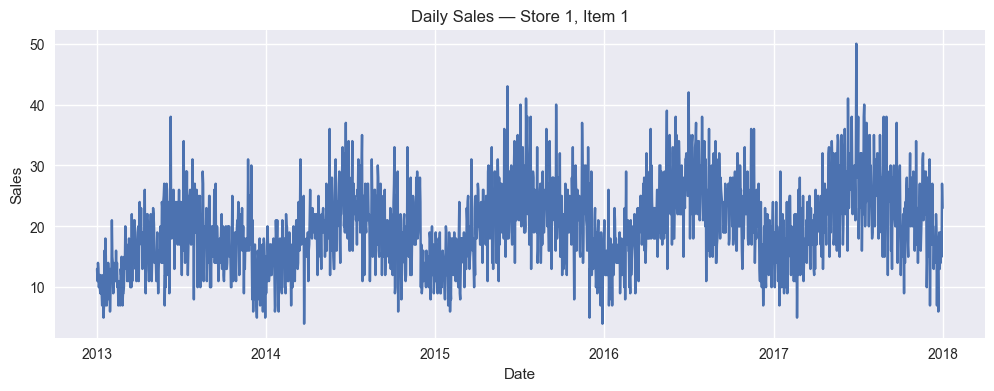

In [7]:
example = df[(df["store"] == 1) & (df["item"] == 1)]

plt.figure(figsize=(12,4))
plt.plot(example["date"], example["sales"])
plt.title("Daily Sales — Store 1, Item 1")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.show()


# Block 4 — Lag Feature Engineering

##  Block 4.1 - Sort values


In [8]:
df = df.sort_values(by=["store", "item", "date"]).reset_index(drop=True)


## Block 4.2 - Lag features


In [9]:
LAGS = [1, 7, 14, 28]

for lag in LAGS:
    df[f"lag_{lag}"] = (
        df.groupby(["store", "item"])["sales"]
          .shift(lag)
    )

## Block 4.3 - Check NaNs introduced by lags

In [10]:

df[[f"lag_{lag}" for lag in LAGS]].isna().sum()


lag_1       500
lag_7      3500
lag_14     7000
lag_28    14000
dtype: int64

## Block 4.4 - Sales vs lag_7 relationship


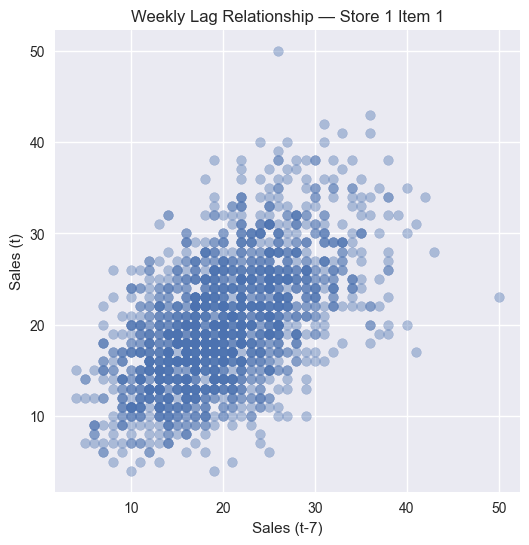

In [11]:
sample = df[(df["store"] == 1) & (df["item"] == 1)].dropna()

plt.figure(figsize=(6,6))
plt.scatter(sample["lag_7"], sample["sales"], alpha=0.4)
plt.xlabel("Sales (t-7)")
plt.ylabel("Sales (t)")
plt.title("Weekly Lag Relationship — Store 1 Item 1")
plt.show()


Lag features capture the autoregressive nature of sales.
Weekly and monthly lags reveal strong seasonality patterns, which are typical in retail demand forecasting.
These features form the backbone of classical and machine learning forecasting models.

The scatter plot between current sales and sales from 7 days earlier reveals a strong positive correlation, indicating clear weekly seasonality. This confirms that past sales provide meaningful information for predicting future demand. Such autoregressive behavior is typical in retail time series and justifies the inclusion of lag-based features in forecasting models.


# Block 5 Rolling Window Features

## 5.1 Rolling statistics

In [12]:
# Ensure data is sorted
df = df.sort_values(["store", "item", "date"])

rolling_windows = [7, 14, 28]

for window in rolling_windows:
    df[f"rolling_mean_{window}"] = (
        df
        .groupby(["store", "item"])["sales"]
        .transform(lambda x: x.shift(1).rolling(window).mean())
    )

    df[f"rolling_std_{window}"] = (
        df
        .groupby(["store", "item"])["sales"]
        .transform(lambda x: x.shift(1).rolling(window).std())
    )


## 5.2 Example visualization

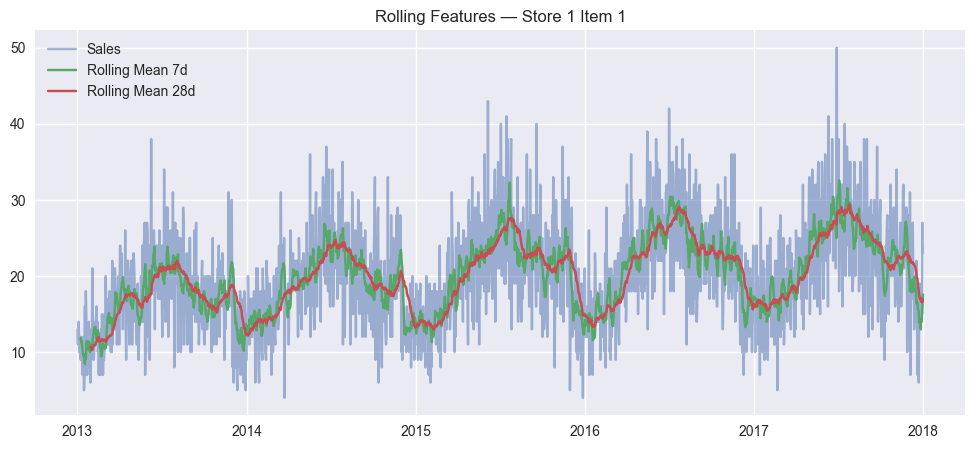

In [13]:
subset = df[(df["store"] == 1) & (df["item"] == 1)].copy()

plt.figure(figsize=(12,5))
plt.plot(subset["date"], subset["sales"], label="Sales", alpha=0.5)
plt.plot(subset["date"], subset["rolling_mean_7"], label="Rolling Mean 7d")
plt.plot(subset["date"], subset["rolling_mean_28"], label="Rolling Mean 28d")
plt.legend()
plt.title("Rolling Features — Store 1 Item 1")
plt.show()

- Rolling means highlight underlying demand trends.

- Larger windows provide stronger smoothing

- Rolling standard deviation captures demand volatility

- Combined with lag features, these variables provide temporal context for forecasting models

# Block 6 – Calendar & Seasonality Features

## 6.1 Temporal Variable Extraction

In [14]:
df["day_of_week"] = df["date"].dt.dayofweek
df["week_of_year"] = df["date"].dt.isocalendar().week.astype(int)
df["month"] = df["date"].dt.month
df["year"] = df["date"].dt.year


## 6.2 Exploratory analysis, sales by day of week 

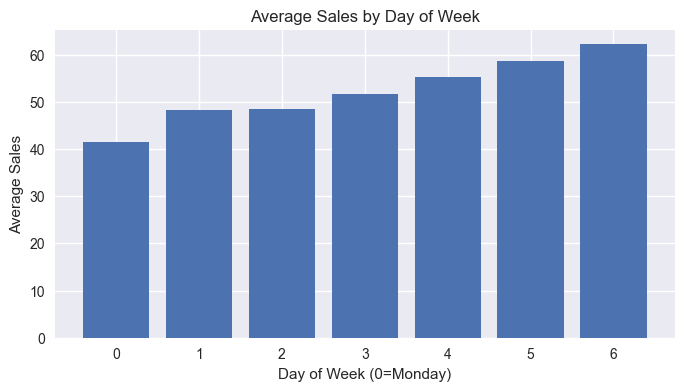

In [15]:
dow_sales = (
    df.groupby("day_of_week")["sales"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8,4))
plt.bar(dow_sales["day_of_week"], dow_sales["sales"])
plt.xlabel("Day of Week (0=Monday)")
plt.ylabel("Average Sales")
plt.title("Average Sales by Day of Week")
plt.show()


- Clear differences are observed in average sales levels depending on the day of the week.

- These patterns reflect recurring consumer behaviors.

- Calendar variables help models to better generalize over time.

# Block 7 – Feature Summary & Dataset Ready for Modeling

## 7.1 Feature Overview

At this point, the dataset includes the following groups of variables:

**Original variables**
- `date`
- `store`
- `item`
- `sales`

**Time-based features**
- `day_of_week`
- `week_of_year`
- `month`
- `year`

**Lag features**
- `lag_1`
- `lag_7`
- `lag_14`
- `lag_28`

**Rolling window features**
- `rolling_mean_7`
- `rolling_mean_14`
- `rolling_mean_28`

These features allow the model to capture seasonality, short-term dependencies, and longer-term demand trends.


## 7.2 Missing Values Check

Lag and rolling window features introduce missing values at the beginning of each (store, item) time series.

In [16]:
df.isna().sum().sort_values(ascending=False)


rolling_std_28     14000
lag_28             14000
rolling_mean_28    14000
rolling_std_14      7000
rolling_mean_14     7000
lag_14              7000
rolling_std_7       3500
rolling_mean_7      3500
lag_7               3500
lag_1                500
store                  0
date                   0
sales                  0
item                   0
day_of_week            0
week_of_year           0
month                  0
year                   0
dtype: int64

## 7.3 Final Dataset Cleaning

Rows containing missing values are removed to ensure a clean and consistent dataset for model training.

In [18]:
df_model = df.dropna().copy()

## 7.4 Feature Matrix and Target Definition

The final feature matrix and target variable are defined as follows:

In [19]:
features = [
    "day_of_week",
    "week_of_year",
    "month",
    "year",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_28"
]

X = df_model[features]
y = df_model["sales"]


## Block 8 – Conclusions

### 8.1 Summary of Findings

In this notebook, we explored and prepared the Store Item Demand dataset for time series modeling.  
Through exploratory analysis and feature engineering, we identified clear temporal patterns and constructed meaningful predictors for demand forecasting.

Key insights include:
- Strong seasonality at weekly and yearly levels.
- Clear differences in demand behavior across stores and items.
- The importance of historical demand information for predicting future sales.

---

### 8.2 Value of Feature Engineering

The creation of lag and rolling window features significantly enriches the dataset:
- Lag features capture short-term demand dependencies.
- Rolling averages smooth noise and highlight underlying trends.
- Time-based features allow models to learn seasonal effects.

Together, these features transform a simple time series into a structured supervised learning problem.

---

### 8.3 Limitations

Some limitations should be noted:
- Removing rows with missing values reduces the size of the training data for early periods.
- External factors such as promotions, holidays, or weather are not included in the dataset.
- The analysis assumes stable store and item behavior over time.

---

### 8.4 Next Steps

In the next notebook, we will:
- Build baseline forecasting models.
- Establish performance benchmarks.
- Compare different modeling approaches for demand prediction.

This will allow us to evaluate how well engineered features translate into predictive performance.

---

### 8.5 Final Remarks

This notebook lays a solid foundation for demand forecasting.  
The structured feature set and clear temporal patterns make the dataset well-suited for both classical time series models and machine learning approaches.


# Block 9 Save Dataset

In [26]:
df.to_pickle("../data/processed/demand_features.pkl")
